In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/CPH100 Data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3.zip"
EXTRACT_DIR = "/content/CPH100_data"

!mkdir -p "$EXTRACT_DIR"
!unzip -o "$ZIP_PATH" -d "$EXTRACT_DIR"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive:  /content/drive/MyDrive/CPH100 Data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3.zip
 extracting: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/LICENSE.txt  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/SHA256SUMS.txt  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/department.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/diagnosis.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/icd10_excluded.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicin

In [ ]:
#import libraries
import torch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier
import xgboost as xgb
plt.rcdefaults()
GLOBALSEED = 42

In [ ]:
cd CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3

[Errno 2] No such file or directory: 'CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3'
/content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3


In [ ]:
#import schemas and data (around 1 minute to load)
# schemas = pd.read_csv("schema.csv")
operations = pd.read_csv("operations.csv")
# vitals = pd.read_csv("vitals.csv")
# department = pd.read_csv("department.csv")
# icd10_excluded = pd.read_csv("icd10_excluded.csv")
labs = pd.read_csv("labs.csv")
medications = pd.read_csv("medications.csv")
# parameters = pd.read_csv("parameters.csv")
ward_vitals = pd.read_csv("ward_vitals.csv")
diagnosis = pd.read_csv("diagnosis.csv")
operations.head()

/tmp/ipython-input-2789391318.py:8: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  medications = pd.read_csv("medications.csv")


,op_id,subject_id,hadm_id,case_id,opdate,age,sex,weight,height,race,...,admission_time,discharge_time,anstart_time,anend_time,cpbon_time,cpboff_time,icuin_time,icuout_time,inhosp_death_time,allcause_death_time
0,484069807,178742874,229842382,NaN,0,30,F,50.0,155.0,Asian,...,0,7195,1120.0,1235.0,NaN,NaN,NaN,NaN,NaN,NaN
1,446270725,158995752,257857903,NaN,0,70,M,45.0,170.0,Asian,...,0,70555,1345.0,1540.0,NaN,NaN,1550.0,19595.0,69860.0,106560.0
2,406892271,108553242,200664328,NaN,61920,50,F,70.0,165.0,Asian,...,0,178555,62170.0,62370.0,NaN,NaN,NaN,NaN,NaN,718560.0
3,478413008,133278262,277235295,NaN,0,35,F,55.0,NaN,Asian,...,0,5755,215.0,340.0,NaN,NaN,NaN,NaN,NaN,NaN
4,468516791,116924034,299190423,NaN,17280,45,F,45.0,150.0,Asian,...,0,25915,17950.0,18070.0,NaN,NaN,NaN,NaN,NaN,NaN


# XGBoost Implementation

In [ ]:
working_table = operations.sort_values("orin_time", ascending=True).drop_duplicates(subset=['subject_id'])
print(f"Operation table # rows: {operations.shape[0]}")
print(f"Working table (only first operation) # rows: {working_table.shape[0]}")

Operation table # rows: 130960
Working table (only first operation) # rows: 99886


In [ ]:
# working_table["died30"] = (working_table['inhosp_death_time'] < (working_table['orout_time'] + 30 * 24 * 60)).astype("int") #credit: https://github.com/vitaldb/inspire/blob/main/gbm_mortality.py
working_table["died30"] = ~working_table['icuin_time'].isna()
# filter out asa >= 6
working_table = working_table[working_table["asa"] < 6]
print(f"Working table (only first operation, no ASA >= 6) # rows: {working_table.shape[0]}")
print(f"Number of deaths within 30 days + No ASA 6: {working_table['died30'].sum()}")
print(f"Percent of deaths within 30 days: {working_table['died30'].sum() / working_table.shape[0]}")

Working table (only first operation, no ASA >= 6) # rows: 97260
Number of deaths within 30 days + No ASA 6: 10785
Percent of deaths within 30 days: 0.1108883405305367


In [ ]:
working_table['bmi'] = (working_table['weight'] / (working_table['height'] / 100) ** 2).fillna(20)
# Fix: Only update the 'bmi' column for out-of-range values
working_table.loc[(working_table['bmi'] > 40) | (working_table['bmi'] < 5), 'bmi'] = 20

#labs table features credit: https://github.com/vitaldb/inspire/blob/main/gbm_mortality.py
for item in ('hb', 'platelet', 'aptt', 'wbc', 'ptinr', 'glucose', 'bun',
             'albumin', 'ast', 'alt', 'creatinine', 'sodium', 'potassium'):
  working_table = pd.merge_asof(working_table.sort_values("orin_time"), labs[labs['item_name'] == item].sort_values("chart_time"),
                              left_on='orin_time', right_on='chart_time', by='subject_id',
                              direction='backward', tolerance=6* 30 * 24 * 60)
  working_table[f'diff_{item}'] = working_table['orin_time'] - working_table['chart_time']
  working_table = working_table.rename(columns={'value': item})
  working_table = working_table.drop(columns=['item_name', 'chart_time'])
working_table.head()

working_table['sex'] = (working_table['sex'] == 'M').astype(int)

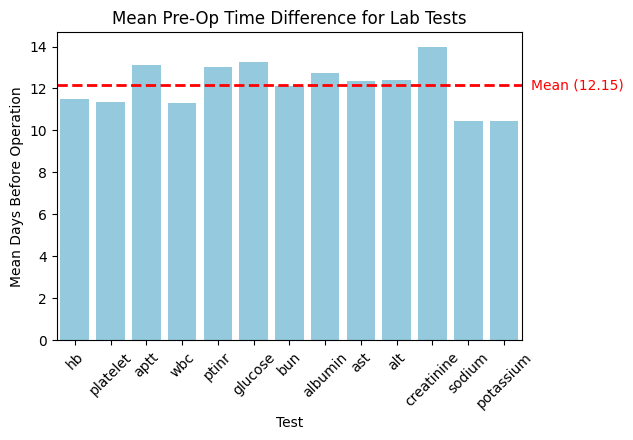

In [ ]:

# sns.histplot(data=working_table[working_table['diff_aptt'] < 10], x="diff_aptt", bins=10)
tests = ['hb', 'platelet', 'aptt', 'wbc', 'ptinr', 'glucose', 'bun',
             'albumin', 'ast', 'alt', 'creatinine', 'sodium', 'potassium']

mean_days = {}

for item in tests:
    mean_days[item] = (working_table[f'diff_{item}'] / (60*24)).mean()

df_plot = pd.DataFrame({
    'test': mean_days.keys(),
    'mean_days': mean_days.values()
})

plt.figure(figsize=(6,4))
sns.barplot(data=df_plot, x='test', y='mean_days', color='skyblue')
plt.axhline(df_plot['mean_days'].mean(), color='red', linestyle='--', linewidth=2)
plt.ylabel("Mean Days Before Operation")
plt.xlabel("Test")
plt.title("Mean Pre-Op Time Difference for Lab Tests")
plt.xticks(rotation=45)
plt.text(
    x=12.75, y=df_plot['mean_days'].mean() - 0.2, s=f"Mean ({df_plot['mean_days'].mean():.2f})",
    color='red',
    fontsize=10
)

In [ ]:
#add ward vitals
for item in ('bt', 'hr', 'nibp_dbp', 'nibp_mbp', 'nibp_sbp', 'rr', 'spo2'):
  working_table = pd.merge_asof(working_table.sort_values("orin_time"), ward_vitals[ward_vitals['item_name'] == item].sort_values("chart_time"),
                              left_on='orin_time', right_on='chart_time', by='subject_id',
                              direction='backward', tolerance=6* 30 * 24 * 60)
  working_table = working_table.rename(columns={'value': item})
  working_table = working_table.drop(columns=['item_name', 'chart_time'])

In [ ]:
# diagnosis['icd10_cm'].value_counts()

In [ ]:
#required library for comorbidity calculation
!pip install git+https://github.com/vvcb/comorbidipy.git@c676a8067ce343704d75bcf8180f9baa1ac47664
from comorbidipy.calculator import comorbidity

  Cloning https://github.com/vvcb/comorbidipy.git (to revision c676a8067ce343704d75bcf8180f9baa1ac47664) to /tmp/pip-req-build-qv84863v
  Running command git clone --filter=blob:none --quiet https://github.com/vvcb/comorbidipy.git /tmp/pip-req-build-qv84863v
  Running command git rev-parse -q --verify 'sha^c676a8067ce343704d75bcf8180f9baa1ac47664'
  Running command git fetch -q https://github.com/vvcb/comorbidipy.git c676a8067ce343704d75bcf8180f9baa1ac47664
  Resolved https://github.com/vvcb/comorbidipy.git to commit c676a8067ce343704d75bcf8180f9baa1ac47664
  Preparing metadata (setup.py) ... done


In [ ]:
op_dx = working_table[['op_id', 'subject_id', 'orin_time', 'age']].merge(
    diagnosis[['subject_id', 'chart_time', 'icd10_cm']], on='subject_id', how='left'
)

op_dx = op_dx[(op_dx['chart_time'].notna()) & (op_dx['chart_time'] <= op_dx['orin_time'])
]

dx_for_cci = op_dx[['op_id', 'icd10_cm','age']].rename(columns={'op_id': 'id',
                                                                'icd10_cm': 'code'})

cci_df = comorbidity(dx_for_cci,
    id='id',
    code='code',
    score='charlson',
    icd='icd10',
    variant='quan',
    weighting='quan',
    age='age'
)

cci_df = cci_df.rename(columns={'id': 'op_id', 'comorbidity_score': 'charlson_cci'})

working_table = working_table.merge(cci_df[['op_id', 'charlson_cci']], on='op_id', how='left'
)

working_table['charlson_cci'] = working_table['charlson_cci'].fillna(0).astype(int)
working_table['charlson_cci'].describe()

,charlson_cci
count,97260.000000
mean,0.757763
std,1.197023
min,0.000000
25%,0.000000
50%,0.000000
75%,2.000000
max,9.000000


/tmp/ipython-input-784463762.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('cci_bin')['died30']
/tmp/ipython-input-784463762.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=icu_rates, x='cci_bin', y='died30', palette='Blues');


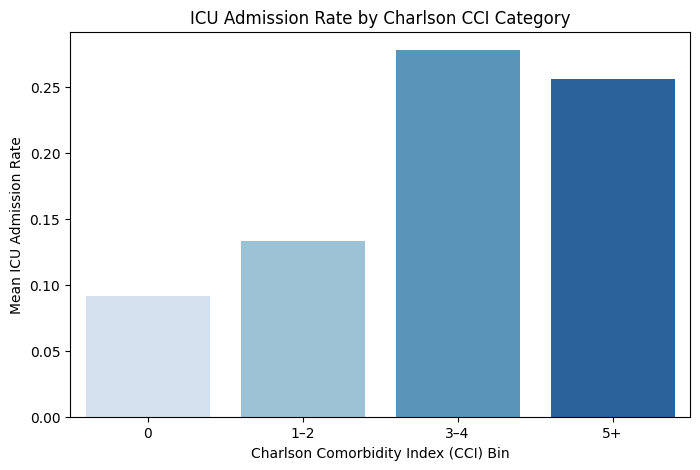

In [ ]:
bins = [-1, 0, 2, 4, 100]
labels = ['0', '1-2', '3-4', '5+']
working_table['cci_bin'] = pd.cut(working_table['charlson_cci'], bins=bins, labels=labels)
icu_rates = working_table.groupby('cci_bin')['died30'].mean().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(data=icu_rates, x='cci_bin', y='died30', palette='Blues');
plt.ylabel("Mean ICU Admission Rate")
plt.xlabel("Charlson Comorbidity Index (CCI) Bin")
plt.title("ICU Admission Rate by Charlson CCI Category")

In [ ]:
meds = medications[['subject_id','chart_time','atc_code']].copy()

op_meds = working_table[['op_id','subject_id','orin_time']].merge(meds, on='subject_id', how='left')
op_meds = op_meds[op_meds['chart_time'].notna() & (op_meds['chart_time'] <= op_meds['orin_time'])]

op_meds['is_immuno'] = op_meds['atc_code'].str.startswith('L04A').fillna(False).astype(int)
op_meds['is_anticoag'] = op_meds['atc_code'].str.startswith('B01A').fillna(False).astype(int)

flags = op_meds.groupby('op_id')[['is_immuno','is_anticoag']].max().reset_index()

working_table = working_table.merge(flags, on='op_id', how='left')
working_table[['is_immuno','is_anticoag']] = working_table[['is_immuno','is_anticoag']].fillna(0).astype(int)
working_table[['is_immuno','is_anticoag']].describe()

/tmp/ipython-input-2040788342.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  op_meds['is_immuno'] = op_meds['atc_code'].str.startswith('L04A').fillna(False).astype(int)
/tmp/ipython-input-2040788342.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  op_meds['is_anticoag'] = op_meds['atc_code'].str.startswith('B01A').fillna(False).astype(int)


,is_immuno,is_anticoag
count,97260.000000,97260.000000
mean,0.008565,0.056858
std,0.092149,0.231572
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,1.000000,1.000000


/tmp/ipython-input-2472595116.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=icu_rates.sort_values('icu_rate'), x='med_group', y='icu_rate', palette='Blues')


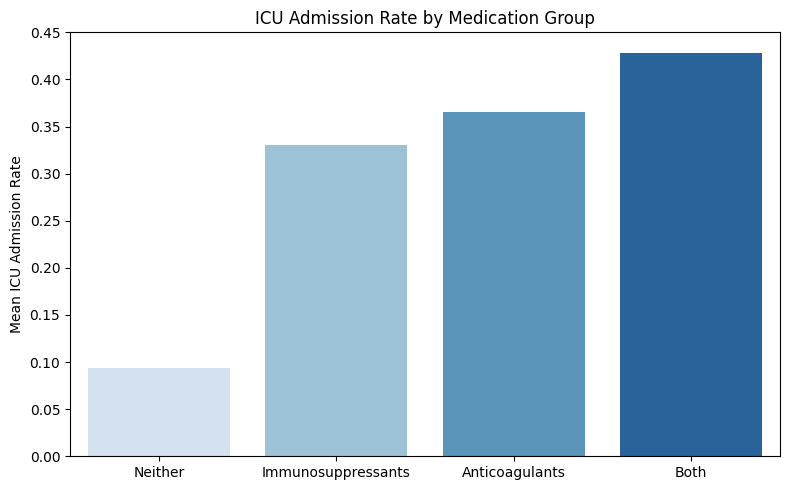

In [ ]:
def med_group(row):
    if row['is_immuno'] == 1 and row['is_anticoag'] == 1:
        return 'Both'
    elif row['is_immuno'] == 1:
        return 'Immunosuppressants'
    elif row['is_anticoag'] == 1:
        return 'Anticoagulants'
    else:
        return 'Neither'

working_table['med_group'] = working_table.apply(med_group, axis=1)

icu_rates = working_table.groupby('med_group')['died30'].mean().reset_index().rename(columns={'died30':'icu_rate'})

plt.figure(figsize=(8,5))
sns.barplot(data=icu_rates.sort_values('icu_rate'), x='med_group', y='icu_rate', palette='Blues')
plt.title('ICU Admission Rate by Medication Group')
plt.ylabel('Mean ICU Admission Rate')
plt.xlabel('')

In [ ]:
predictor = 'died30'
features = ['age', 'sex', 'emop', 'bmi', 'hb', 'platelet', 'wbc', 'aptt',
            'ptinr', 'glucose', 'bun', 'albumin', 'ast', 'alt', 'creatinine', 'sodium', 'potassium',
            'bt', 'hr', 'nibp_dbp', 'nibp_mbp', 'nibp_sbp', 'rr', 'spo2', 'charlson_cci', 'is_immuno','is_anticoag']

X = working_table[features]
y = working_table[predictor]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
# y_train, y_test = y_train[predictor], y_test[predictor]

In [ ]:
model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.02,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="auc",
    early_stopping_rounds=50,
    enable_categorical=True
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=True
)

best_val_auc = model.best_score
best_round = model.best_iteration

print(f"Best Validation AUC: {best_val_auc:.5f} at iteration {best_round}")
test_pred = model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_pred)

print(f"Test AUC: {test_auc:.5f}")

[0]	validation_0-auc:0.82284
[1]	validation_0-auc:0.83565
[2]	validation_0-auc:0.84244
[3]	validation_0-auc:0.84522
[4]	validation_0-auc:0.84652
[5]	validation_0-auc:0.84539
[6]	validation_0-auc:0.84796
[7]	validation_0-auc:0.84900
[8]	validation_0-auc:0.84941
[9]	validation_0-auc:0.84967
[10]	validation_0-auc:0.85010
[11]	validation_0-auc:0.84999
[12]	validation_0-auc:0.85010
[13]	validation_0-auc:0.85030
[14]	validation_0-auc:0.85035
[15]	validation_0-auc:0.85072
[16]	validation_0-auc:0.85089
[17]	validation_0-auc:0.85125
[18]	validation_0-auc:0.85125
[19]	validation_0-auc:0.85113
[20]	validation_0-auc:0.85093
[21]	validation_0-auc:0.85092
[22]	validation_0-auc:0.85131
[23]	validation_0-auc:0.85145
[24]	validation_0-auc:0.85160
[25]	validation_0-auc:0.85170
[26]	validation_0-auc:0.85185
[27]	validation_0-auc:0.85239
[28]	validation_0-auc:0.85262
[29]	validation_0-auc:0.85267
[30]	validation_0-auc:0.85274
[31]	validation_0-auc:0.85276
[32]	validation_0-auc:0.85286
[33]	validation_0-au

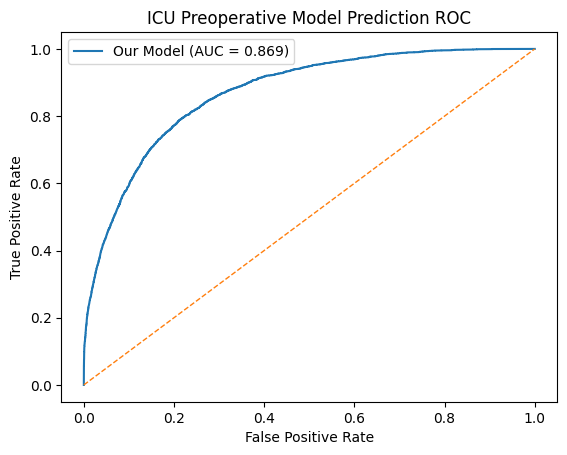

In [ ]:
fpr_gbm, tpr_gbm, _ = roc_curve(y_test, test_pred)
plt.plot(fpr_gbm, tpr_gbm, label=f"Our Model (AUC = {np.round(test_auc,3)})")
plt.plot([0, 1], [0, 1], lw=1, linestyle='--')
plt.legend()
plt.title("ICU Preoperative Model Prediction ROC")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

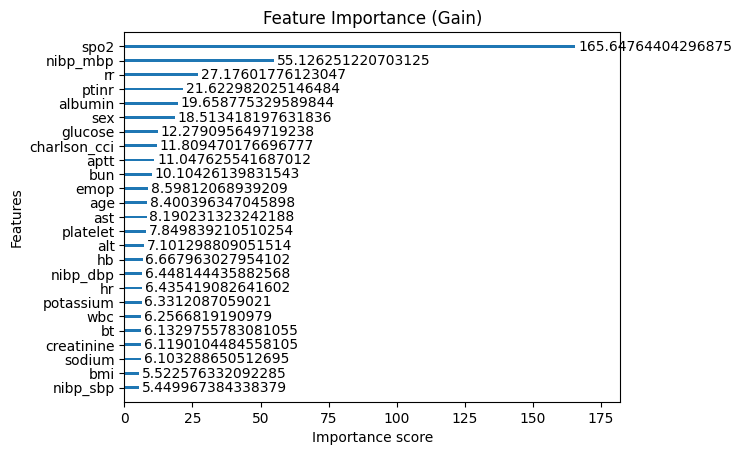

In [ ]:
# plt.rcParams['figure.figsize'] = [14, 6]
xgb.plot_importance(model, importance_type='gain')
plt.grid(False)
plt.title("Feature Importance (Gain)")
# plt.xlim(0, 40)
plt.rcdefaults()

/usr/local/lib/python3.12/dist-packages/xgboost/plotting.py:267: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` insetad. 
  warnings.warn(


<Axes: >

<Figure size 6000x6000 with 0 Axes>

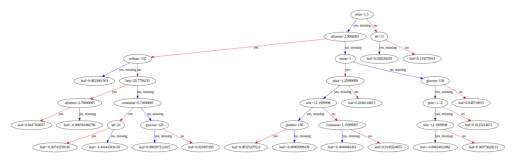

In [ ]:
# plt.rcParams['figure.figsize'] = [30, 30]
# plt.rcParams['font.size'] = 14
plt.figure(figsize=(60, 60))
xgb.plot_tree(model, num_trees = 3)